In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import xarray as xr
from tqdm.auto import tqdm

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
import src.horizontal_regions as regions

plt.style.use('seaborn-v0_8-poster')

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
# df_at3d = pd.DataFrame()

# ## This is really slow bc of
# ## 1) Concat on every loop
# ## 2) Double merge
# ## 3) Late filter (drop extinction <= 0.3 earlier)
# ## My thinking (todo) is to put the labeled clouds into the dataframe
# ## Then, I can group by label for each altitude and calculate cloud area 
# ## & compare to in situ chord length
# for r in tqdm(list(exset.retrievals.values())):
#     tmp_cld = r.solvers_retrieval[0.67].medium['cloud'].copy(deep=True)
#     # labels, _ = regions.label_per_slice(tmp_cld.extinction.data > 0.3)
#     # tmp_cld['labels'] = (['x', 'y', 'z'], labels)
#     tmp_df = tmp_cld.extinction.to_dataframe()
#     tmp_df['source'] = r.exp_name
#     tmp_vc = xr.load_dataset(r.root_dir / 'min_optical_path.nc').min_optical_path.to_dataframe()
#     tmp_df = pd.merge(
#         tmp_df.reset_index().loc[:,['x','y','z','extinction','source']], 
#         tmp_vc.reset_index().loc[:,['x','y','z','min_optical_path']], 
#         on=['x','y','z']
#     )
#     # tmp_df = pd.merge(
#     #     tmp_df.reset_index().loc[:,['x','y','z','extinction','source', 'min_optical_path']], 
#     #     tmp_cld.to_dataframe().reset_index().loc[:,['x','y','z','labels']], 
#     #     on=['x','y','z']
#     # )
#     df_at3d = pd.concat([df_at3d, tmp_df[tmp_df['extinction'] > 0.3]])

# df_at3d = df_at3d.reset_index()
# df_at3d['x'] *= 1000
# df_at3d['y'] *= 1000
# df_at3d['z'] *= 1000
# df_at3d['isVeiled'] = df_at3d['min_optical_path'] >= 5

In [5]:
cvm = exset.get_retrieval('default').cvm.drop_vars(['delx', 'dely'])
cvm['cloud_top_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).max(dim="z")
cvm['distance_to_cloud_top'] = cvm.z - cvm.cloud_top_heights
cvm['cloud_base_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).min(dim="z")
cvm['distance_to_cloud_base'] = cvm.z - cvm.cloud_base_heights
distance_to_cloud = cvm.distance_to_cloud_base.clip(max=0) + cvm.distance_to_cloud_top.clip(min=0)
cvm["distance_to_cloud"] = distance_to_cloud
cvm = cvm.drop_vars(['cloud_top_heights', 'cloud_base_heights'])
cvm = cvm.to_dataframe()
df_list = []

for r in list(exset.retrievals.values()):
    tmp_ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.copy(deep=True)
    df_tmp = tmp_ext.drop_vars(['reff', 'veff']).to_dataframe()
    df_tmp = df_tmp.join(cvm)
    tmp_vc = xr.load_dataset(r.root_dir / 'min_optical_path.nc').min_optical_path.to_dataframe()
    df_tmp = df_tmp.join(tmp_vc)
    df_tmp['source'] = r.exp_name
    df_list.append(df_tmp[df_tmp['extinction'] >= 0.3])

df_at3d = pd.concat(df_list)

df_at3d = df_at3d.reset_index()
df_at3d['x'] *= 1000
df_at3d['y'] *= 1000
df_at3d['z'] *= 1000

bins = np.arange(-50, 1451, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)

dtc_bins = np.arange(-0.45, 1.051, 0.1)
df_at3d['distance_to_cloud_bin'] = pd.cut(df_at3d['distance_to_cloud'], bins=dtc_bins)

df_at3d['isVeiled'] = df_at3d['min_optical_path'] >= 5

df_at3d.loc[(df_at3d['source'] == 'unconstrained') & (df_at3d['cloud_volume_mask'] == 1),'source'] = 'unconstrained in cvm'
df_at3d.loc[(df_at3d['source'] == 'unconstrained') & (df_at3d['cloud_volume_mask'] == 0),'source'] = 'unconstrained out cvm'

In [6]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
df_p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
df_p3['source'] = 'in situ'

# The sample at time t is part of the cloud element e if
# the extinction at time t > 0.3 
# and there is another sample t' \in e such that |t-t'| < 3
# In other words, it takes 3 seconds of clear air to separate two clouds
df_p3['sample_optical_path'] = df_p3['ext_km'] * df_p3['Length_m'] * 1e-3
ext_th = 0.3
t_th = pd.Timedelta(3, 's')
df_p3['cloud_pass'] = -1
cloud_pass = 1
inCloud = False
t_last_cloud = df_p3.index[0]
for row in df_p3.itertuples():
    if(not inCloud):
        if(row.ext_km > ext_th):
            inCloud = True
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
    else:
        if(row.ext_km > ext_th):
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        elif(row.Index - t_last_cloud < t_th):
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        else:
            df_p3.loc[t_last_cloud+pd.Timedelta(1, 's'):row.Index, 'cloud_pass'] = -1
            inCloud = False
            cloud_pass += 1

g = df_p3.groupby('cloud_pass')['sample_optical_path']
df_p3['forward_optical_path'] = g.cumsum()
df_p3['backward_optical_path'] = g.apply(lambda s: s[::-1].cumsum()[::-1]).reset_index(level=0, drop=True)
df_p3['optical_path'] = df_p3[['forward_optical_path', 'backward_optical_path']].min(axis=1)
df_p3['pass_length'] = df_p3.groupby('cloud_pass')['Length_m'].transform('sum')
df_p3['isVeiled'] = df_p3['optical_path'] >= 5

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)
/tmp/ipykernel_1919365/3987540596.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['cloud_pass'] = -1
/tmp/ipykernel_1919365/3987540596.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['forward_optical_path'] = g.cumsum()
/tmp/ipykernel_1919365/3987540596.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result o

In [7]:
bins = np.arange(350, 1151, 100)
# bins = np.arange(-50, 1451, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)
df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)

/tmp/ipykernel_1919365/868679857.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)


In [8]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

df_p3_sub = df_p3[
    # (p3['N_L'] > 10000)
    (df_p3['ext_km'] > 0.3)
    & (df_p3.index > start_time)
    & (df_p3.index < end_time)
    & (df_p3['GPS_Altitude'] < 1250)
    # & (p3['optical_path'] < 5)       # Remove P3 veiled core
    # & (p3['pass_length'] < 3600)
    & ~(
        ((df_p3.index >= pd.to_datetime('2019-10-02 00:35:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 00:36:00')))
        | ((df_p3.index >= pd.to_datetime('2019-10-02 01:45:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 01:46:30')))
    )
]
df_p3_sub = df_p3_sub.reset_index().rename(columns={'ext_km':'extinction'})

In [9]:
# (np.pi * (0.5 * df_p3_sub.drop_duplicates(subset='cloud_pass')['pass_length'])**2).plot.hist()

In [10]:
df_p3_at3d = pd.concat([
    df_at3d.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled']],
    df_p3_sub.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled']] #.groupby('altitude_bin').filter(lambda x: len(x) > 10)
])

In [11]:
# Rename sources
df_p3_at3d.loc[df_p3_at3d['source'] == 'default','source'] = 'AT3D'
df_p3_at3d.loc[df_p3_at3d['source'] == 'surf4p0','source'] = 'surf. wind 0.67 m/s -> 4.0 m/s'
df_p3_at3d.loc[df_p3_at3d['source'] == 'aod0p150','source'] = 'AOD 0.2 -> 0.15'
df_p3_at3d.loc[df_p3_at3d['source'] == 'periodic','source'] = 'open -> periodic'
df_p3_at3d.loc[df_p3_at3d['source'] == 'unconstrained in cvm','source'] = 'constrained -> unconstrained in cvm'
df_p3_at3d.loc[df_p3_at3d['source'] == 'unconstrained out cvm','source'] = 'constrained -> unconstrained out cvm'


In [12]:
for i, name in enumerate(exset.retrievals.keys()):
    print(f'{i}: {name}')

0: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/aerosol/aod0p150
1: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/aerosol/aod0p250
2: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/CVM/unconstrained
3: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/HBC/periodic
4: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/surf_wind/surf4p0_obsolete
5: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/surf_wind/surf4p0
6: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/default_obsolete
7: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/default


/tmp/ipykernel_1919365/2241006782.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_1919365/2241006782.py:62: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == True].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_1919365/2241006782.py:88: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to 

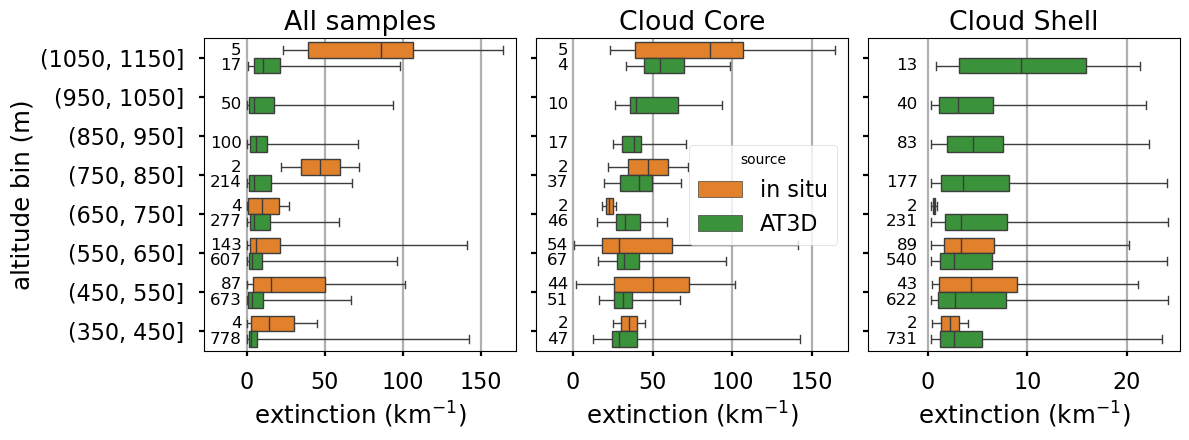

In [13]:
# pltlist = ['in situ', 'default', 'surf4p0', 'aod0p150', 'periodic', 'unconstrained in cvm', 'unconstrained out cvm']
# pltlist = ['in situ', 'default', 'surf. wind 0.67 m/s -> 4.0 m/s', 'AOD 0.2 -> 0.15', 'open -> periodic', 'constrained -> unconstrained in cvm', 'constrained -> unconstrained out cvm']
pltlist = ['in situ', 'AT3D']

box_kwargs = {
    'x': 'extinction',
    'y': 'altitude_bin',
    'hue': 'source',
    'hue_order': pltlist,
    'palette': {
        'in situ': 'tab:orange',
        'default': 'tab:green',
        'AT3D': 'tab:green',
        'periodic': 'tab:blue',
        'open -> periodic': 'tab:blue',
        'unconstrained in cvm': 'tab:red',
        'constrained -> unconstrained in cvm': 'tab:red',
        'unconstrained out cvm': 'tab:pink',
        'constrained -> unconstrained out cvm': 'tab:pink',
        'aod0p150': 'tab:orange',
        'AOD 0.2 -> 0.15': 'tab:orange',
        'surf4p0': 'tab:purple',
        'surf. wind 0.67 m/s -> 4.0 m/s': 'tab:purple'
    },
    'order': [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)],
    'whis':(0, 100)
}
text_fs = 12

f, ax = plt.subplots(1, 3, figsize=(12,4.5), sharex=False, sharey=True)
sns.boxplot(df_p3_at3d[df_p3_at3d['source'].isin(pltlist)], ax=ax[0], legend=False, **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[0].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=text_fs)

ax[0].set_xlim(-27, None)
ax[0].set_ylabel('altitude bin (m)')
ax[0].set_xlabel(r'extinction (km$^{-1}$)')
ax[0].set_title('All samples')
ax[0].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == True)], ax=ax[1], legend=True, **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == True].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[1].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=text_fs)

ax[1].set_xlim(-23, None)
# ax[1].set_ylabel('altitude bin (m)')
ax[1].set_xlabel(r'extinction (km$^{-1}$)')
ax[1].set_title('Cloud Core')
ax[1].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == False)], ax=ax[2], legend=False, **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == False].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[2].text(-1, y_pos, f'{count}', ha='right', va='center', fontsize=text_fs)

ax[2].set_xlim(-6, None)
ax[2].set_ylabel('altitude bin (m)')
ax[2].set_xlabel(r'extinction (km$^{-1}$)')
ax[2].set_title('Cloud Shell')
ax[2].grid(axis='x')

f.tight_layout()